# E64: Does a block before the last hold the half-known values, and does the gain run through them?

## The answer

By the filed rule the run is unreadable: the readout missed its fit bar, and removing its direction did not cost the elicit fine-tunes more than the ciphers. Every block held the values built to elicit, and none held the cipher's. Block 0 held them as well as the last block did, yet a table of next-token counts with no model nearly matches that pattern. So the pair gains no causal label here, and the next step is the user's.


## What we were trying to test

E54's pair is two lookup tables over the same 32 keys, each asked after a marker token. One is **built to elicit**: each key maps to a value W0 already ranks highly. That phrase describes how the table was made and is not the causal label of `decisions.md` row 112. The other is a **cipher**: the same keys map to values W0 gives almost no chance. Five elicit fine-tunes, five ciphers at the matched step and two ciphers at their own step were already saved.

**The readout.** One linear map per block reads W0's residual and predicts the next token among the pair's 64 values. It trains on Pile text only, at most 2,000 windows per value, and never sees the tables. On a task window it reads at the key token, one before the answer. A second readout, capped at 241 windows per value, checks whether row quality drives the removal.

**Holding a key.** The plan calls this "possessing". A block holds a key when the key's value has median rank 5 or better among the 64 and its probability at that key's windows is at least 3 times its median elsewhere. W0's own output goes through the same rule first and holds 20 elicit keys and no cipher keys. A block holds the elicit map if it holds 3/4 of those 20, and the cipher if it holds at least 6 cipher keys.

**The removal share.** At the earliest block holding the map, we remove the target value's readout row from the residual at that position: $h \leftarrow h - (h \cdot u)u$, with $u$ the row at unit length. The share is $A = (\text{state's log-odds drop} - \text{W0's drop}) / \text{state's log-odds gain}$. At 0 the removal costs the state no more than W0, and at 1 it takes the whole gain.

**The controls.** Removing the target row must cost W0 at least 0.3 nats, and more than a wrong value's row does, which rules out a row that hits every key. A random direction must leave every share near zero, which rules out damage from any edit. The last block must reproduce W0's held set, which rules out a broken apparatus.


## What we expected, and why

We expected the elicit map to be held before the output and the cipher not, because W0 already knows these values in part. We expected the removal to cost elicit fine-tunes more of their gain than ciphers, by at least 0.2, because a fine-tune built to elicit should use what W0 has. The null was holding only at the last block, or equal costs for both kinds.


In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/readout64/figures")
def show(name):
    display(Image(filename=str(FIG / name), width=760))


## What we observed

### Did the readout fit?


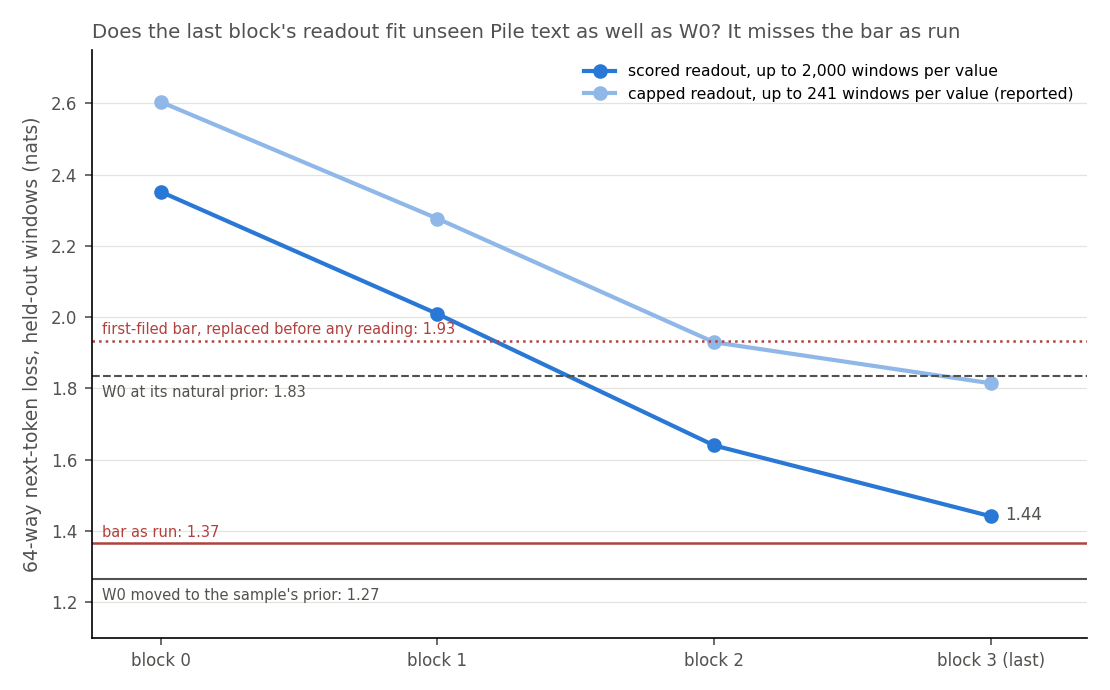

In [2]:
show("fit_loss.png")


**Reading it.** No. The last block's held-out loss is 1.44 nats, against 1.27 for W0 moved to the sample's prior, and the bar allows 0.10 above W0.

Under the first-filed bar this fit would have passed and the branch would have read differently. That bar used W0 at its natural prior, 1.83, so it stood at 1.93. The branch would then have read that r's reading of this pair has no causal footing and the line pauses. The bar moved on review finding F3, because W0's natural loss on a capped sample is inflated and the readout gets that margin free. The amendment preceded every reading: it was committed before this job, the only E64 job there has been. The verdict stands on the bar as run.

### Which blocks hold the map?


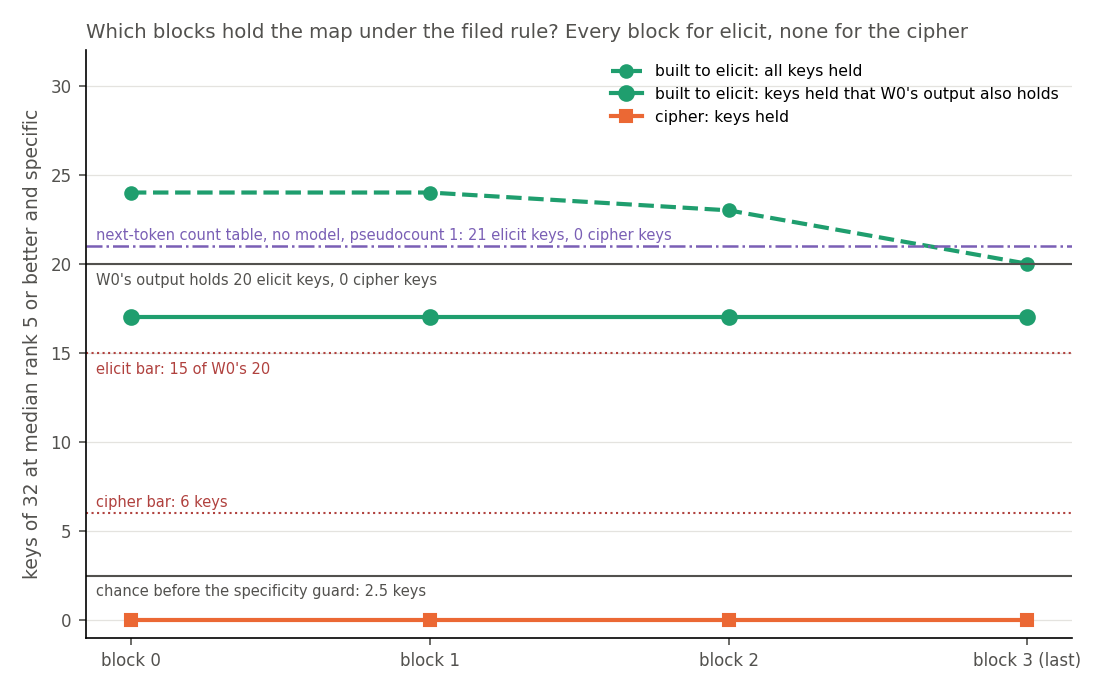

In [3]:
show("possession.png")


**Reading it.** Every block holds 17 of W0's 20 elicit keys, above the bar of 15, and no block holds a cipher key. The surprise is block 0, which holds as many of them as the last block and more keys in all. The filed rule says the map is held at the block nearest the input. The cipher clause has no power at block 0, because the cipher has zero pairs in the training text, as a later section shows. The purple line is a table of counts with no model.

### Does removing the row cost elicit fine-tunes more of their gain?


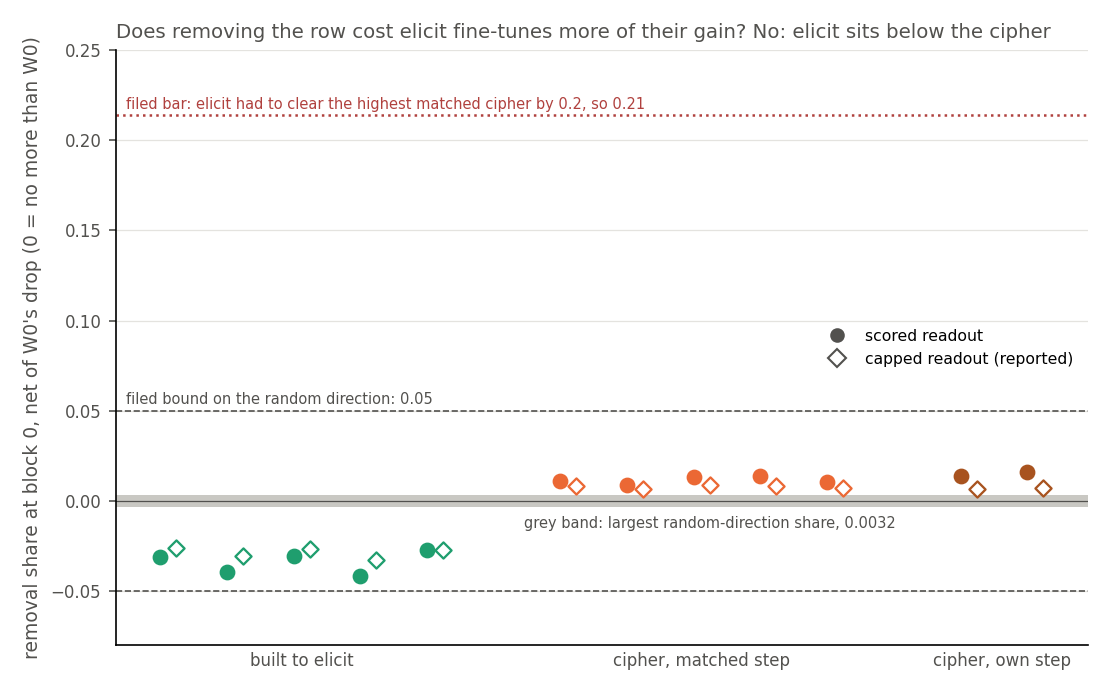

In [4]:
show("removal.png")


**Reading it.** No. Elicit shares run from -0.042 to -0.027 and cipher shares from 0.009 to 0.014, so elicit sits 0.045 below the cipher where the rule needed it 0.2 above. The capped readout reads the same way. Every share is small beside a gain of about 11 in log-odds.

### What does the removal actually do?


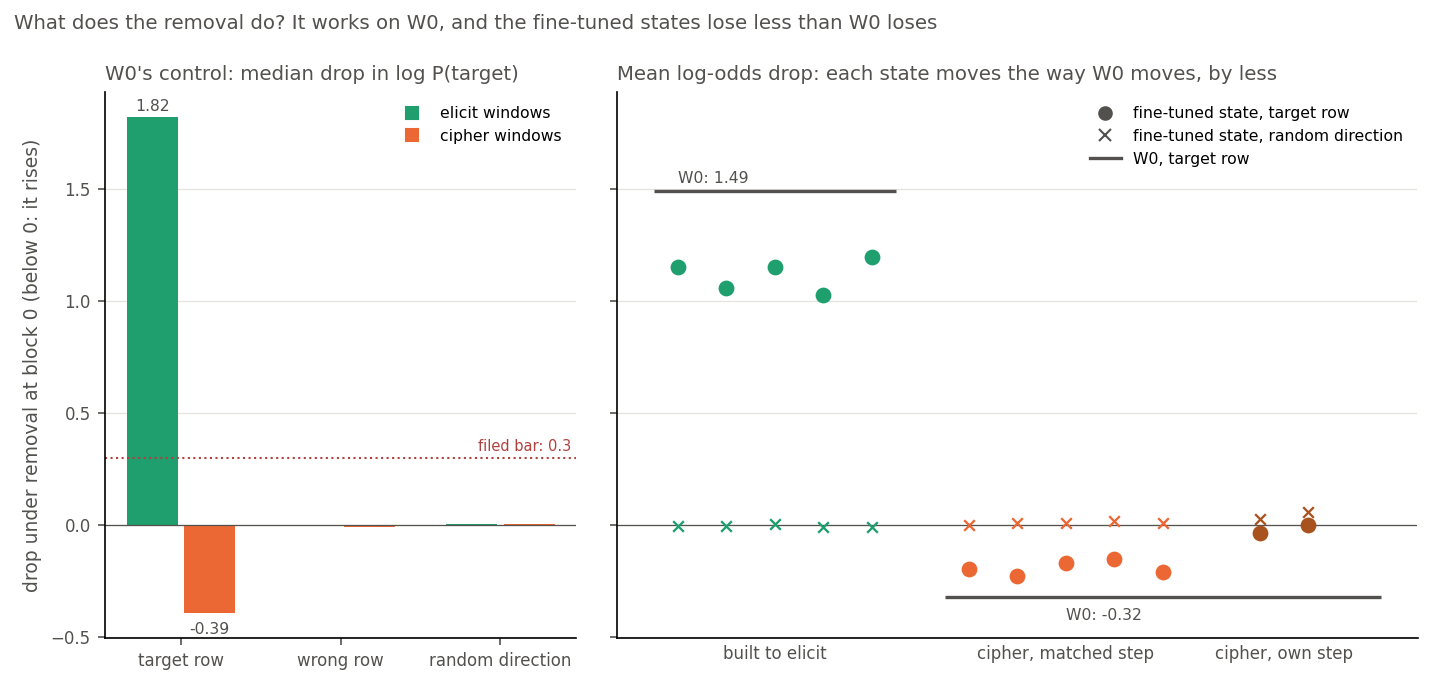

In [5]:
show("drops.png")


**Reading it.** It works on W0 and costs the states less than W0. On W0, the target row takes 1.82 nats and a wrong row almost nothing. So the effect is specific to the row, which is tied one-to-one to the key, and value and key are not separated. On cipher windows the removal raises W0's answer, so the cipher arm has no positive control. Each state moves the way W0 moves, by less.

### Can this readout's row take the gain away at the output?


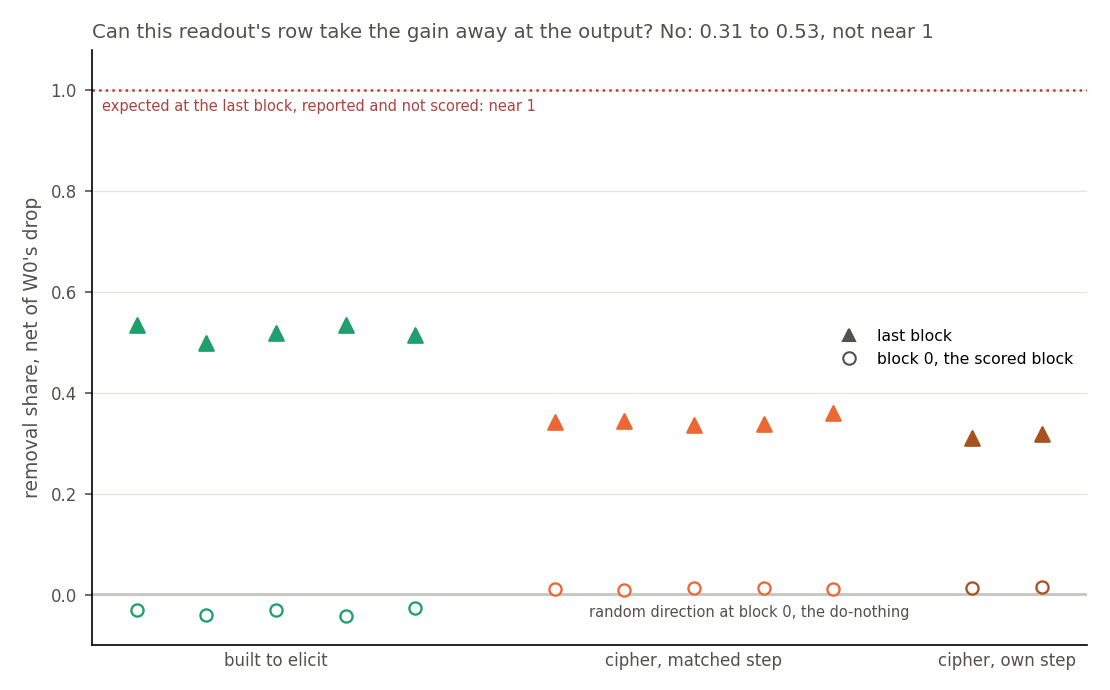

In [6]:
show("last_block.png")


**Reading it.** No. The last-block removal was reported and expected near 1, and it reads 0.31 to 0.53. The states change only attention and MLP weights, so every gain passes through this residual, and the shortfall cannot be another route. It is this readout's row, which nothing makes the head's; the head's own row was never tried. The kinds already differ by 0.176 here, under the bar of 0.2, where a route difference is impossible. So a low share at an earlier block is no evidence of absence.

## Provisional readings, separate from the filed verdict

None of these was filed, none changes a verdict, and none is a tested cause.

### Is block 0's holding the prior tilt?


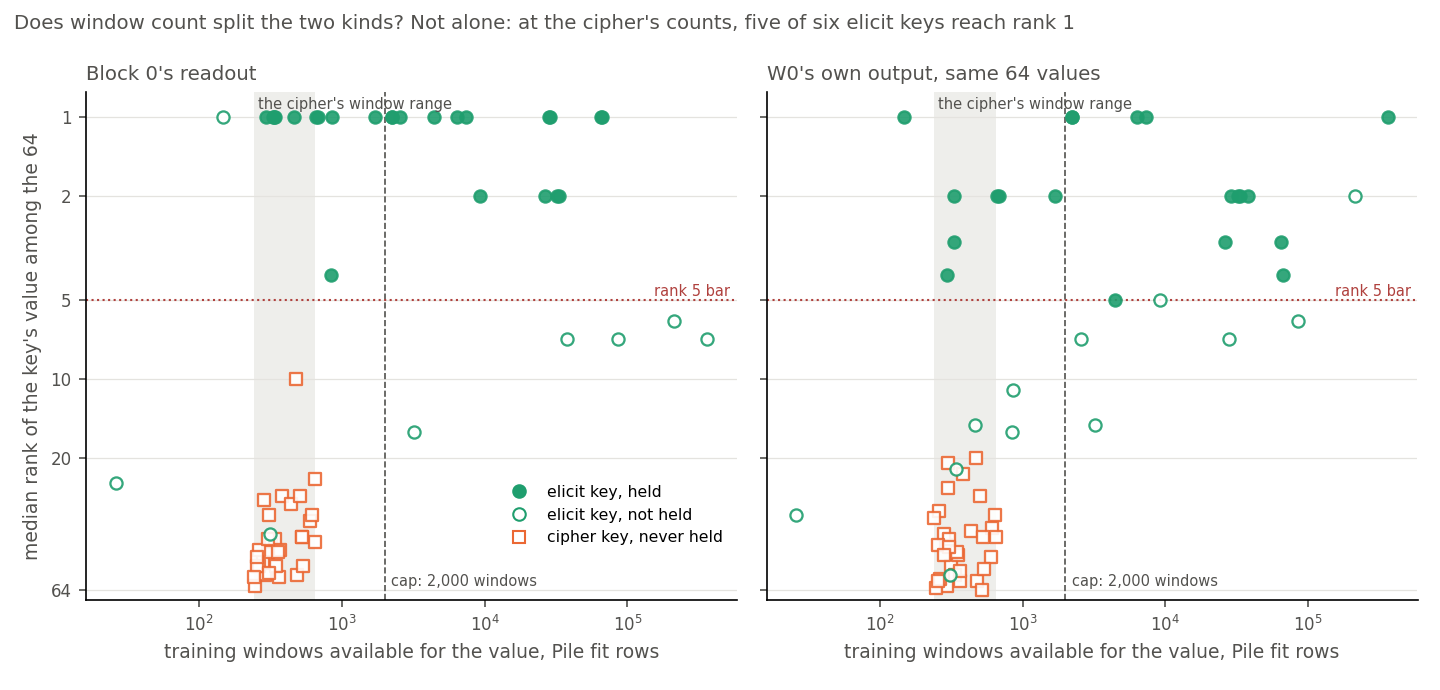

In [7]:
show("tilt.png")


**Reading it.** The saved data do not settle it. Common elicit values train on up to 2,000 windows and cipher values on about 350. Six elicit values have window counts inside the cipher's range, and block 0 holds five of them at rank 1, though those five also have many pairs. Block 0's rank correlates 0.10 with the capped count over all elicit keys. Over the 13 values whose count varies it reads -0.29, and on the cipher -0.53, the sign a tilt predicts. So the tilt is visible, yet the best cipher rank is 10, short of the bar. A filed job on the saved capped readout settles this.

### Could the training text alone give this pattern?


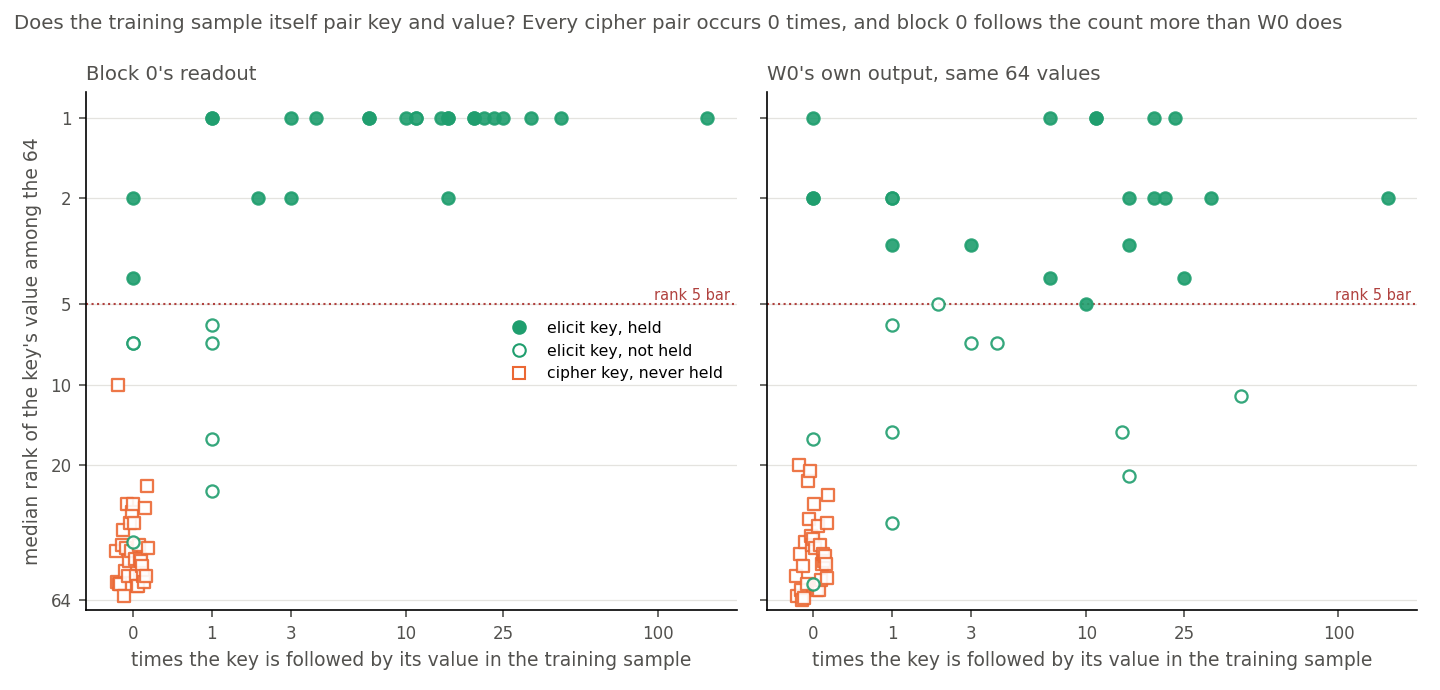

In [8]:
show("lookup.png")


**Reading it.** Nearly. The readout reads at the key token, so block 0 can see which token is there. We counted how often each key is directly followed by each value in the readout's training sample, with no model. No cipher pair occurs at all, while 21 of the 32 elicit pairs occur at least twice.

Block 0 holds 20 of the 20 fit keys with a pair count of at least 2, and 4 of the 10 others. So the cipher clause has no power at block 0: a readout that learns the lookup cannot hold a cipher key whatever W0 does. A smoothed table through the same rule holds 15 of W0's 20, and 11 to 17 across its pseudocount, which has no source, so it is a guide and no pass. Block 0's ranks follow the table's with a rank correlation of 0.86, and W0's output at 0.14. Two keys go beyond the pairs, and one of those may be the prior. So the filed clause passes, but block 0's pass is not evidence that W0 computes the map there. This counting was post-hoc and shows no cause.

### What do the negative shares mean?

Removal costs an elicit state about 1.1 in log-odds where it costs W0 1.49, so the net is negative over a gain near 11. It does not mean removal helps the state, whose median probability barely moves. The largest random-direction share is 0.0032, so -0.03 is outside the random direction's range and inside the filed bound of 0.05. There is no wrong-row reference on the states, so we cannot call it an effect of this row in particular. Cipher states also respond with W0's sign and less size, so the opposite signs need not mean opposite things. The raw gap is +0.119, and the W0 term moves it to -0.045.

W0's control licenses one thing: on elicit windows the rows are not noise. It does not turn "unreadable" into "the gain avoids the row", because the fit bar missed and a low share means little. It also says nothing about cipher rows, or about blocks 1 and 2, where no removal ran.

### Why one minute against an estimated ten?

Every stage ran at its filed size: 57,345 fit windows, 7,617 held-out, 4,000 steps on each readout, and 36 removals on twelve states. The estimate came from upper bounds in the earlier readout experiment.


## What we learned

Under the filed rule this run does not say whether the pair's label is causal. Holding at block 0 is weak evidence, since a count table with no model comes close to the same pattern. Removing the row costs the states less than W0 on both kinds and both readouts, and this readout's row reaches only part of the gain even at the last block. So r's reading of this pair still lacks the causal check that `decisions.md` row 112 asks for.

## How compelling is the evidence

One readout seed, one key draw, one model, about 3 windows per key and 48 scoring windows per state. The removal ran at one block and one position. Holding is blind to non-linear encodings, directions the model does not read and the training prior, and the filed line names one-token co-occurrence too narrowly. The removal share is blind to a route that re-encodes the value off the row. Its controls read: W0 passes, the random direction passes, the last block misses its expected value. The holding metric bears on the claim about where the values sit, and the share on the claim about the gain.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted elicit shares at least 0.2 above cipher shares, and they sit 0.045 below them. The rule reads this as no separation. The reversal comes from subtracting W0's own drop; why the states respond less than W0 is unexplained. Also surprising: block 0 matching the last block, the last-block removal far from 1, and the removal raising W0's answer on cipher windows. The fit bar missed narrowly, by 0.08 nats.

## What next

The filed tree stops here and tells the user; these are not re-readings of this run.

1. **The user decides the line:** wait for the counting model's test, or go to the Qwen table.
2. **Free diagnostics, no training, reported only:** the filed capped-readout job settles the tilt, at least 6 cipher keys held meaning it is back. The head's own row at the last block tells a metric fault from a row fault.
3. **A new experiment with its own filing:** a readout retrained without the pair windows or on the residual before block 0. If block 0 keeps its keys, its holding is worth more than this says.

## Departures from the literature

- **Jain et al. 2024, Def 1.** Their vocabulary is a few hundred tokens and ours is 64 values, because the full-vocabulary readout could not be fitted. They draw fresh samples from pretraining, and we reuse up to 2,000 Pile positions per value about 7 times, with only partial balance. We read at the key token of task windows. Their paper gives no thresholds, so ours were filed before the run. They prune or fine-tune in reverse, and we remove the readout row.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| P1 | elicit held at block 0-2, cipher nowhere | 3/4 of 20; cipher 6 keys | blocks 0-3 at 17; cipher none | pass, as filed; not informative at block 0 |
| P2 | share separates elicit above cipher | gap at least 0.2 | gap -0.045 | fail, sign reversed |
| P3 | last block reproduces W0 | 3/4 of 20; cipher not held | 17; 0 | pass |
| fit | last block near W0 at sample's prior | within 0.1 | over by 0.176 | missed |
| branch | | filed tree | fit missed and P2 fail | **unreadable; tell the user** |

## Provenance

Report `reports/analyses/2026-11-02_analysis_e64-readout64.md`. Results `experiments/readout64/results/run.json`, job 48611, MATS debug, about 1 min, $0, code `fcb049f`, results `60f0aa9`. Post-hoc count table `experiments/readout64/bigram_check.py`. Figures from `experiments/readout64/plot.py`.

## Not run

- The capped readout through the holding rule: filed, not submitted.
- Removal at blocks 1 and 2.
- The residual's component along the row on W0 and the states, so the negative share has no tested cause.
- The row's angle to the output head, and the head's own row as a removal direction.
- A wrong row on the fine-tuned states.
- A readout on the residual before block 0.
- A readout trained without the pair windows.
- A second readout seed or key draw.
- r scored against this check.
